# Reproduce the ladder table

Logistic regression on pooled features of the 394 RRWP-2-blind ladders (98 blind groups,
18-26 atoms), 5 folds grouped by blind group x 3 repeats, folds read from the data
(`cv_fold`). Loads `ladder_afm` / `ladder_fm` with `qgf.data`, recomputes every feature
family and checks each cell against `experiments/ladder/expected/`.

| section | what | time |
|---|---|---|
| 1 | the data | seconds |
| 2 | the paper table (7 feature sets) | ~10 s |
| 3 | every family + permutation test (`RUN_FULL = True`) | ~1 min |

In [1]:
import os
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from qgf.data import load
from qgf.synthetic.benchmark import FULL_TABLE, MAIN_TABLE, METRICS, evaluate, markdown_table
from qgf.synthetic.dataset import benchmark_inputs

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATA = Path(os.environ.get("QGF_DATA", ROOT / "data" / "processed"))

# two categorical slots (validated: CVD dE 24.7); text and axes stay in neutral ink
PIN, FRU, INK, MUTED, EDGE = "#2a78d6", "#eb6834", "#0b0b0b", "#898781", "#c3c2b7"
CLS = {1: ("pinned", PIN), 0: ("frustrated", FRU)}
mpl.rcParams.update(
    {
        "figure.dpi": 120,
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": EDGE,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
    }
)

EXPECTED = pd.read_csv(ROOT / "experiments" / "ladder" / "expected" / "summary.csv")
RUN_FULL = False  # section 3


def check(summary: pd.DataFrame) -> pd.DataFrame:
    """|delta| per cell against the expected summary (means and stds, 3 decimals)."""
    ref = EXPECTED.set_index("family").loc[summary["family"]]
    got = summary.set_index("family")
    cols = [f"{m}_{s}" for m in METRICS for s in ("mean", "std")]
    cols += ["perm_p"] if "perm_p" in got else []
    return (got[cols].round(3) - ref[cols].round(3)).abs()

## 1. The data

In [2]:
afm, fm = load("ladder_afm", root=DATA), load("ladder_fm", root=DATA)
graphs, meta = afm
print(
    f"{len(graphs)} graphs; times {meta['times_ns'][0]:.0f}-{meta['times_ns'][-1]:.0f} ns; "
    f"{meta['emulator']}"
)
sizes = np.array([g.num_nodes for g in graphs])
labels = np.array([int(g.y) for g in graphs])
print(
    pd.crosstab(
        sizes, np.where(labels == 1, "pinned", "frustrated"), rownames=["atoms"], colnames=[""]
    )
)

394 graphs; times 100-4000 ns; emu-mps 2.7.7 (pulser 1.8.0), max bond dimension 16, precision 1e-5, dt = 20 ns, CPU; expectation values of Occupation and CorrelationMatrix (no shots). Validated against exact emu-sv on the 18-24-atom graphs (ROC-AUC within 0.03).
       frustrated  pinned
atoms                    
18              2       2
20              8       8
22             39      39
24             88      88
26             60      60


In [3]:
inputs = benchmark_inputs(afm, fm)
F, y, folds = inputs["F"], inputs["y"], inputs["folds"]
print(
    f"{len(np.unique(inputs['groups']))} blind groups, folds {folds.shape}; "
    f"feature dimensions: " + ", ".join(f"{k} {F[k].shape[1]}" for k, _ in MAIN_TABLE)
)

98 blind groups, folds (394, 3); feature dimensions: rrwp20 600, geom 110, rrwp20+lap+ring+geom 836, fm 600, afm 600, afm+fm 1200, rrwp20+lap+ring+geom+afm+fm 2036


## 2. The paper table

In [4]:
summary, per_fold = evaluate(F, y, folds, [fam for fam, _ in MAIN_TABLE])
display(Markdown(markdown_table(summary, MAIN_TABLE)))
delta = check(summary)
print(f"max |delta| vs expected: {delta.to_numpy().max():.3f}")

| Feature set | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| RRWP | 0.557 ± 0.048 | 0.559 ± 0.047 | 0.612 ± 0.065 |
| Geometry | 0.503 ± 0.053 | 0.495 ± 0.080 | 0.501 ± 0.063 |
| RRWP+Lap+Ring+Geom | 0.641 ± 0.077 | 0.643 ± 0.091 | 0.680 ± 0.065 |
| FM | 0.622 ± 0.063 | 0.620 ± 0.071 | 0.670 ± 0.065 |
| AFM | 0.847 ± 0.045 | 0.849 ± 0.045 | 0.914 ± 0.026 |
| AFM+FM | 0.875 ± 0.043 | 0.875 ± 0.044 | 0.941 ± 0.022 |
| RRWP+Lap+Ring+Geom+AFM+FM | 0.882 ± 0.043 | 0.884 ± 0.043 | 0.941 ± 0.023 |


max |delta| vs expected: 0.000


ROC-AUC per feature set (mean ± std over the 15 test folds). Classical feature sets in
blue, sets with quantum features in orange; the dashed line is chance.

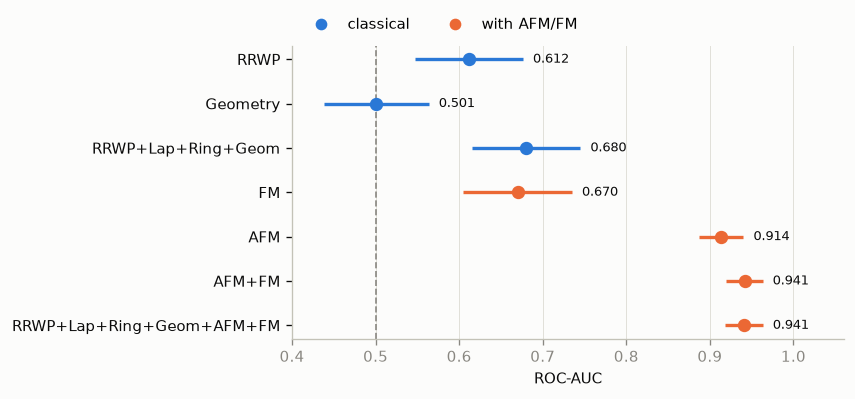

In [5]:
auc = summary.set_index("family")
names = [label for _, label in MAIN_TABLE][::-1]
fams = [fam for fam, _ in MAIN_TABLE][::-1]
quantum = ["afm" in f or "fm" in f.split("+") for f in fams]
fig, ax = plt.subplots(figsize=(7.2, 3.4))
for k, (fam, q) in enumerate(zip(fams, quantum)):
    mean, std = auc.loc[fam, "roc_auc_mean"], auc.loc[fam, "roc_auc_std"]
    col = FRU if q else PIN
    ax.errorbar(mean, k, xerr=std, fmt="o", color=col, ms=7, lw=2, capsize=0)
    ax.text(mean + std + 0.012, k, f"{mean:.3f}", va="center", fontsize=8, color=INK)
ax.axvline(0.5, color=MUTED, lw=1, ls="--")
ax.set(yticks=range(len(names)), yticklabels=names, xlim=(0.4, 1.06), xlabel="ROC-AUC")
ax.tick_params(axis="y", colors=INK)
ax.grid(axis="x", color="#e1e0d9", lw=0.6)
ax.set_axisbelow(True)
for lab, col in (("classical", PIN), ("with AFM/FM", FRU)):
    ax.plot([], [], "o", color=col, label=lab)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
plt.tight_layout()
plt.show()

## 3. Every family + permutation test (`RUN_FULL = True`, ~1 min)

Includes node count, RRWP-2 (blind: exactly 0.500) and RRWP-3, Laplacian, Ring, the
combinations with each RRWP horizon and the ideal ground state; permutation p from 100
label shuffles (floor 0.010).

In [6]:
if RUN_FULL:
    full, _ = evaluate(F, y, folds, [fam for fam, _ in FULL_TABLE], n_perm=100, n_jobs=-1)
    display(Markdown(markdown_table(full, FULL_TABLE)))
    print(f"max |delta| vs expected: {check(full).to_numpy().max():.3f}")
else:
    print((ROOT / "experiments" / "ladder" / "expected" / "table_full.md").read_text())

| Feature set | Accuracy | F1 | ROC-AUC | perm p |
|---|---|---|---|---|
| Node count | 0.500 ± 0.000 | 0.000 ± 0.000 | 0.500 ± 0.000 | 0.604 |
| RRWP-2 (blind horizon) | 0.500 ± 0.000 | 0.000 ± 0.000 | 0.500 ± 0.000 | 0.485 |
| RRWP-3 | 0.586 ± 0.019 | 0.578 ± 0.041 | 0.622 ± 0.043 | 0.010 |
| RRWP-20 | 0.557 ± 0.048 | 0.559 ± 0.047 | 0.612 ± 0.065 | 0.020 |
| Geometry | 0.503 ± 0.053 | 0.495 ± 0.080 | 0.501 ± 0.063 | 0.446 |
| Laplacian | 0.613 ± 0.043 | 0.610 ± 0.070 | 0.657 ± 0.053 | 0.010 |
| Ring | 0.500 ± 0.000 | 0.000 ± 0.000 | 0.500 ± 0.000 | 0.614 |
| RRWP-2+Lap+Ring+Geom | 0.613 ± 0.053 | 0.616 ± 0.064 | 0.674 ± 0.059 | 0.010 |
| RRWP-3+Lap+Ring+Geom | 0.641 ± 0.066 | 0.644 ± 0.075 | 0.699 ± 0.060 | 0.010 |
| RRWP-20+Lap+Ring+Geom | 0.641 ± 0.077 | 0.643 ± 0.091 | 0.680 ± 0.065 | 0.010 |
| FM | 0.622 ± 0.063 | 0.620 ± 0.071 | 0.670 ± 0.065 | 0.010 |
| AFM | 0.847 ± 0.045 | 0.849 ± 0.045 | 0.914 ± 0.026 | 0.010 |
| AFM+FM | 0.875 ± 0.043 | 0.875 ± 0.044 | 0.941 ± 0.022 | 0.01